In [1]:
import pandas as pd
import numpy as np

# データ全体の観察

In [ ]:
df = pd.read_excel("data/Concrete_Data.xlsx")

# ()内の記述削除
df.columns = df.columns.str.replace(r"\s*\([^)]*\)", "", regex=True)

print(f"Shape: {df.shape}")
display(df.head())
display(df.info())
display(df.isna().mean().sort_values(ascending=False)) #欠損率確認
display(df.describe().T)

Shape: (1030, 9)


,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age,Concrete compressive strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.986111
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.269535
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.052780
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.296075


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 9 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Cement                          1030 non-null   float64
 1   Blast Furnace Slag              1030 non-null   float64
 2   Fly Ash                         1030 non-null   float64
 3   Water                           1030 non-null   float64
 4   Superplasticizer                1030 non-null   float64
 5   Coarse Aggregate                1030 non-null   float64
 6   Fine Aggregate                  1030 non-null   float64
 7   Age                             1030 non-null   int64  
 8   Concrete compressive strength   1030 non-null   float64
dtypes: float64(8), int64(1)
memory usage: 72.5 KB


None

Cement                            0.0
Blast Furnace Slag                0.0
Fly Ash                           0.0
Water                             0.0
Superplasticizer                  0.0
Coarse Aggregate                  0.0
Fine Aggregate                    0.0
Age                               0.0
Concrete compressive strength     0.0
dtype: float64

,count,mean,std,min,25%,50%,75%,max
Cement,1030.0,281.165631,104.507142,102.000000,192.375000,272.900000,350.000000,540.000000
Blast Furnace Slag,1030.0,73.895485,86.279104,0.000000,0.000000,22.000000,142.950000,359.400000
Fly Ash,1030.0,54.187136,63.996469,0.000000,0.000000,0.000000,118.270000,200.100000
Water,1030.0,181.566359,21.355567,121.750000,164.900000,185.000000,192.000000,247.000000
Superplasticizer,1030.0,6.203112,5.973492,0.000000,0.000000,6.350000,10.160000,32.200000
Coarse Aggregate,1030.0,972.918592,77.753818,801.000000,932.000000,968.000000,1029.400000,1145.000000
Fine Aggregate,1030.0,773.578883,80.175427,594.000000,730.950000,779.510000,824.000000,992.600000
Age,1030.0,45.662136,63.169912,1.000000,7.000000,28.000000,56.000000,365.000000
Concrete compressive strength,1030.0,35.817836,16.705679,2.331808,23.707115,34.442774,46.136287,82.599225


欠損値(NaN)はない。
ヒストグラムを描き、外れ値、異常値を確認する。


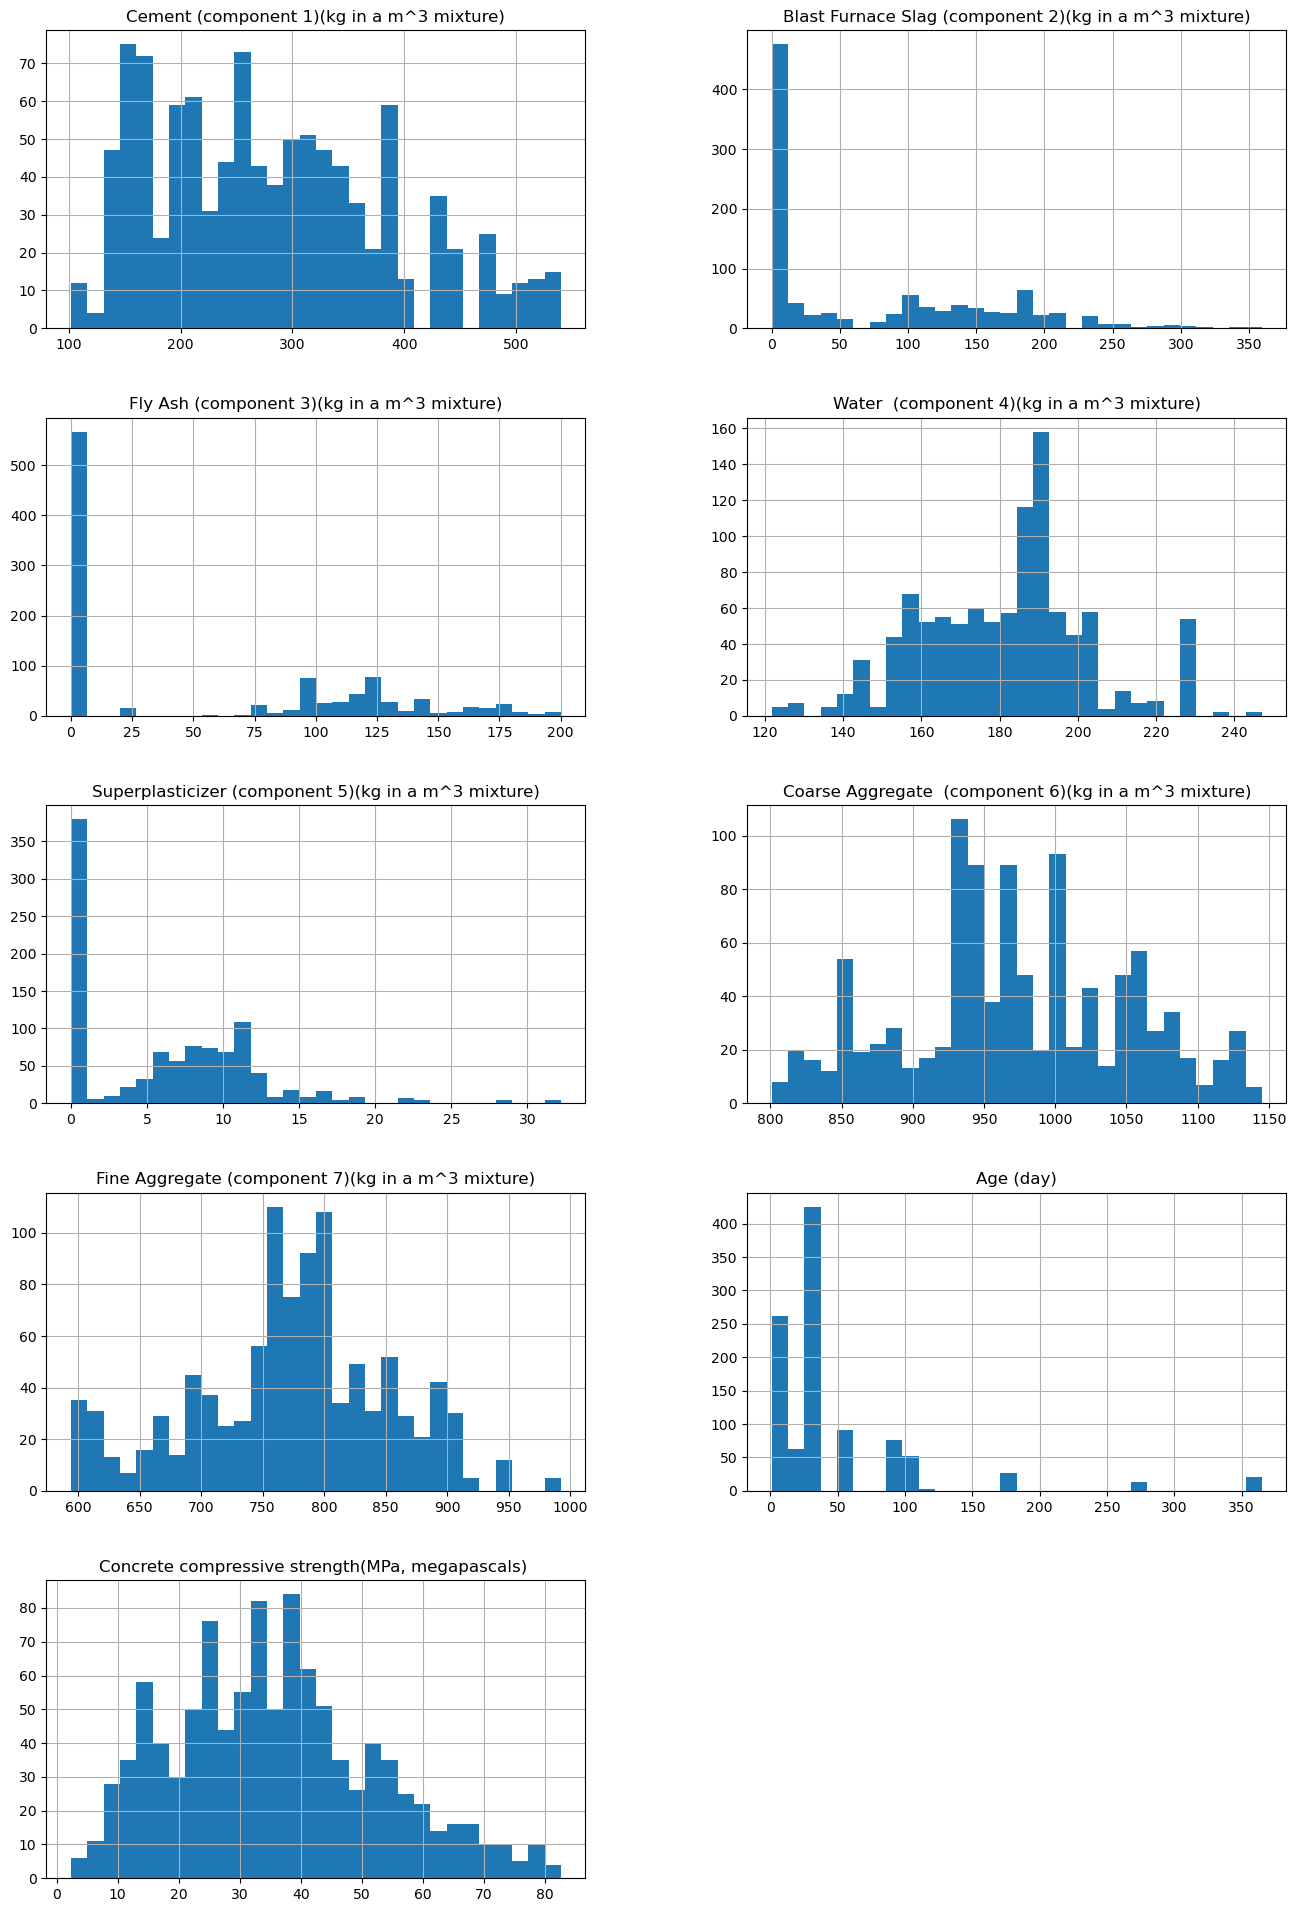

In [4]:
num_cols_all = df.select_dtypes(include="number").columns
n_num_cols = len(num_cols_all)

for i in range(0, n_num_cols, 10):
    # 列数絞って表示
    num_cols = num_cols_all[i:i+10]

    df[num_cols].hist(bins=30, figsize=(16, 24), layout=(5, 2))

"0"の値が多いデータがいくつか存在する。
対象となる変数は以下の3項目である。
　Blast Furnace Slag
　Fly Ash
　Superplasticizer
これらはいずれもコンクリートの配合材料であり、製造において使用されない（"0"になる）場合もあり得る。
そのため、0は材料の未使用を表す有効な配合条件である可能性が高く、
単純に欠損値や異常値として扱うべきではないと判断した。

また、以下で分布およびゼロ値を含むデータの特徴を確認しているが、
現時点では明らかに不自然な値や分布は確認されなかった。

また、相関ヒートマップも確認し、互いに相関が強い項目はないことを確認した。

以上より、これらの0は有効なデータとして保持し、以降の分析およびモデル構築に使用する方針とした。


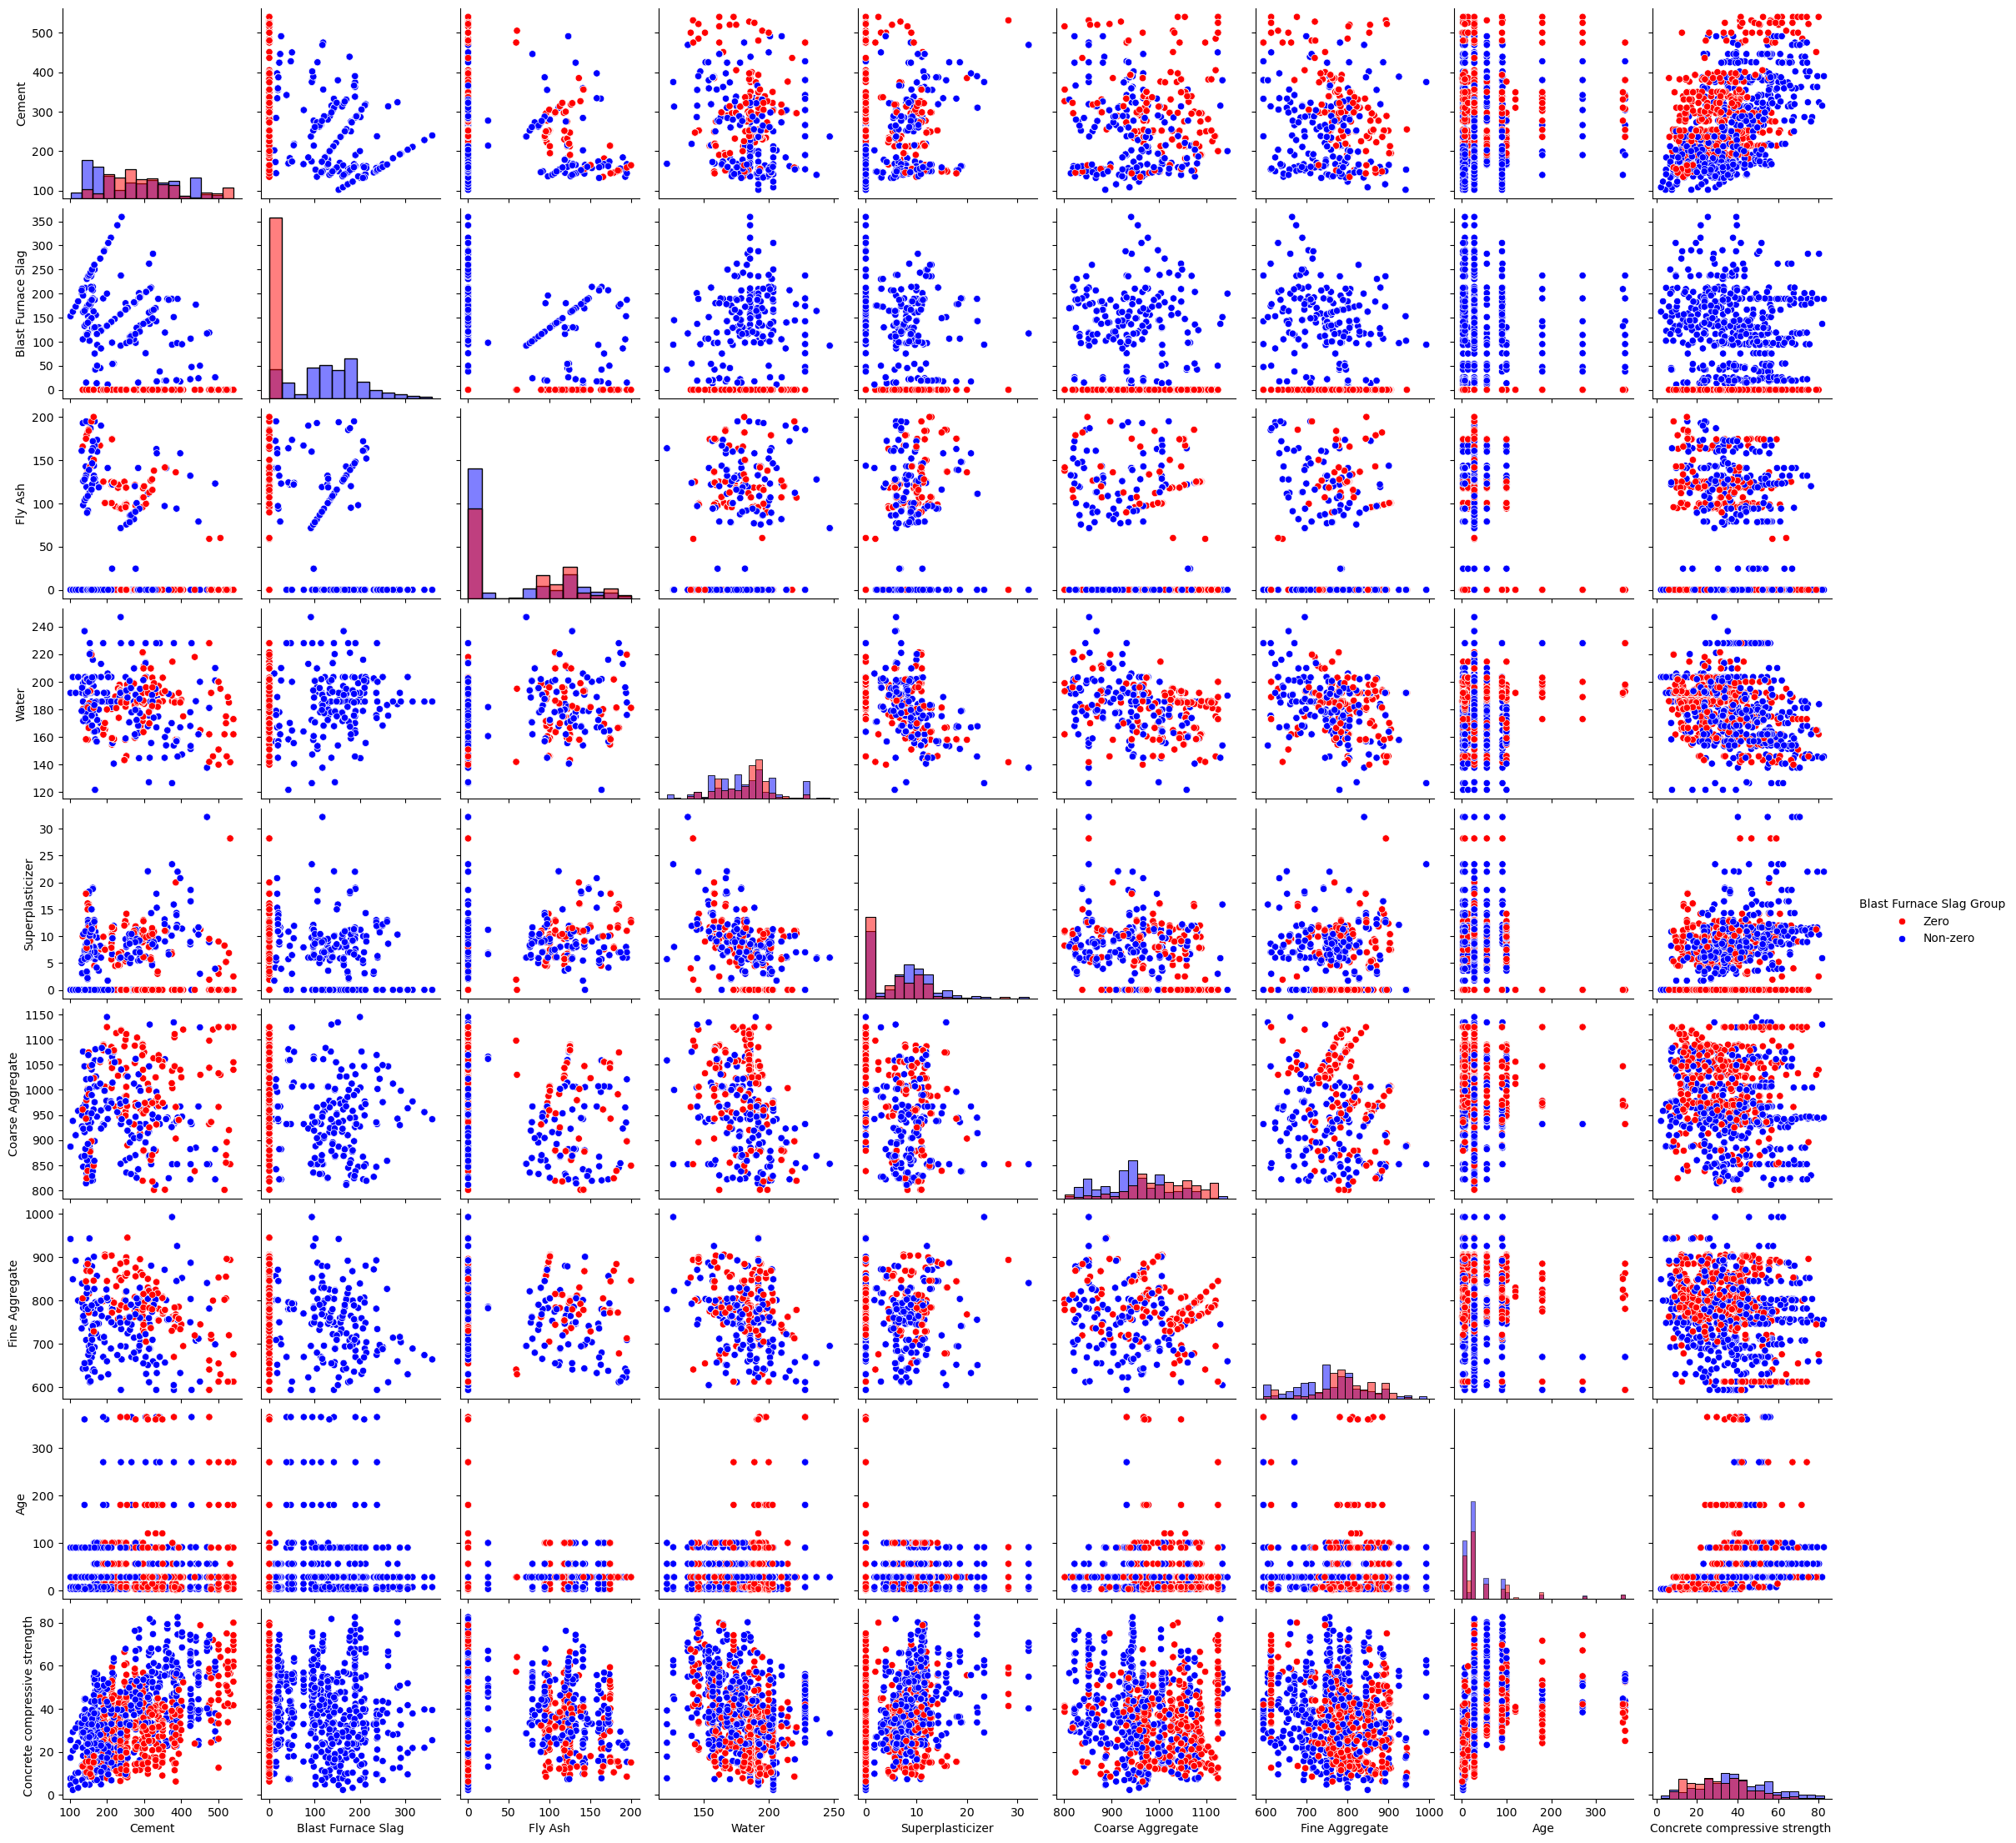

In [10]:
import seaborn as sns
import matplotlib.pyplot as plt

df["Blast Furnace Slag Group"] = df["Blast Furnace Slag"].apply(
    lambda x: "Zero" if x == 0 else "Non-zero"
)

sns.pairplot(
    df,
    hue="Blast Furnace Slag Group",
    diag_kind="hist",
    palette={"Zero": "red", "Non-zero": "blue"}
)

plt.show()

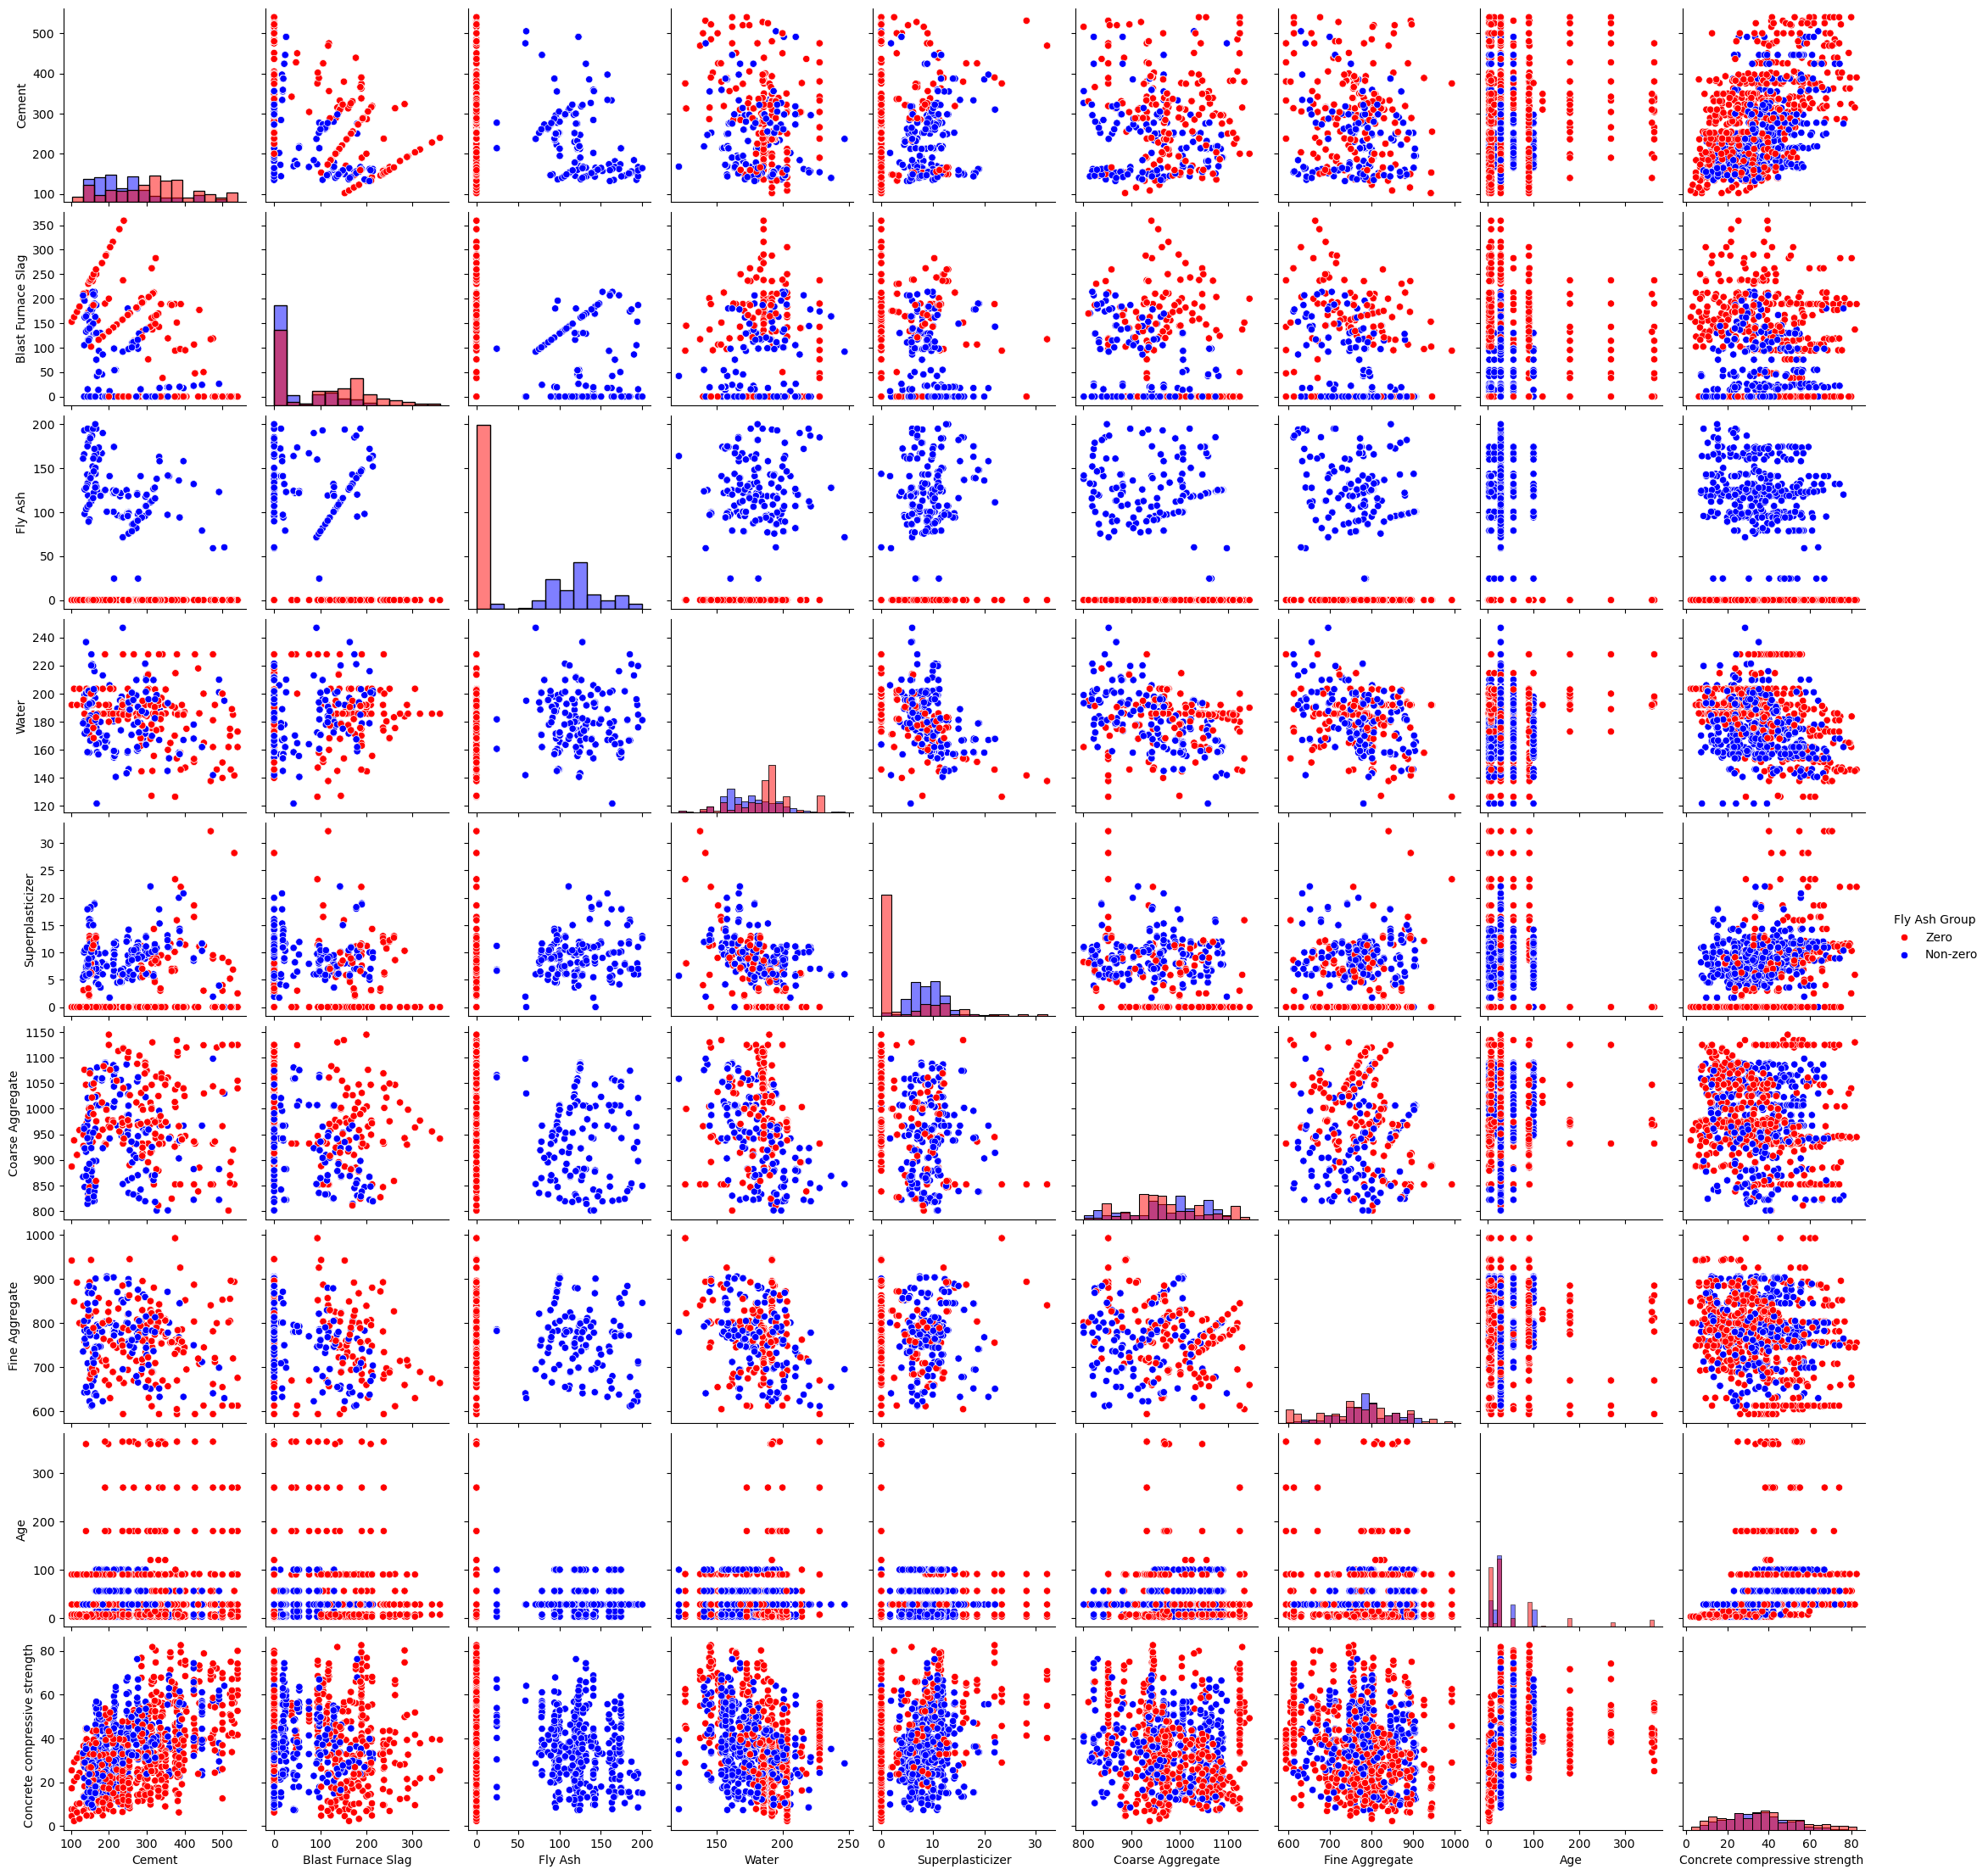

In [11]:
df["Fly Ash Group"] = df["Fly Ash"].apply(
    lambda x: "Zero" if x == 0 else "Non-zero"
)

sns.pairplot(
    df,
    hue="Fly Ash Group",
    diag_kind="hist",
    palette={"Zero": "red", "Non-zero": "blue"}
)

plt.show()

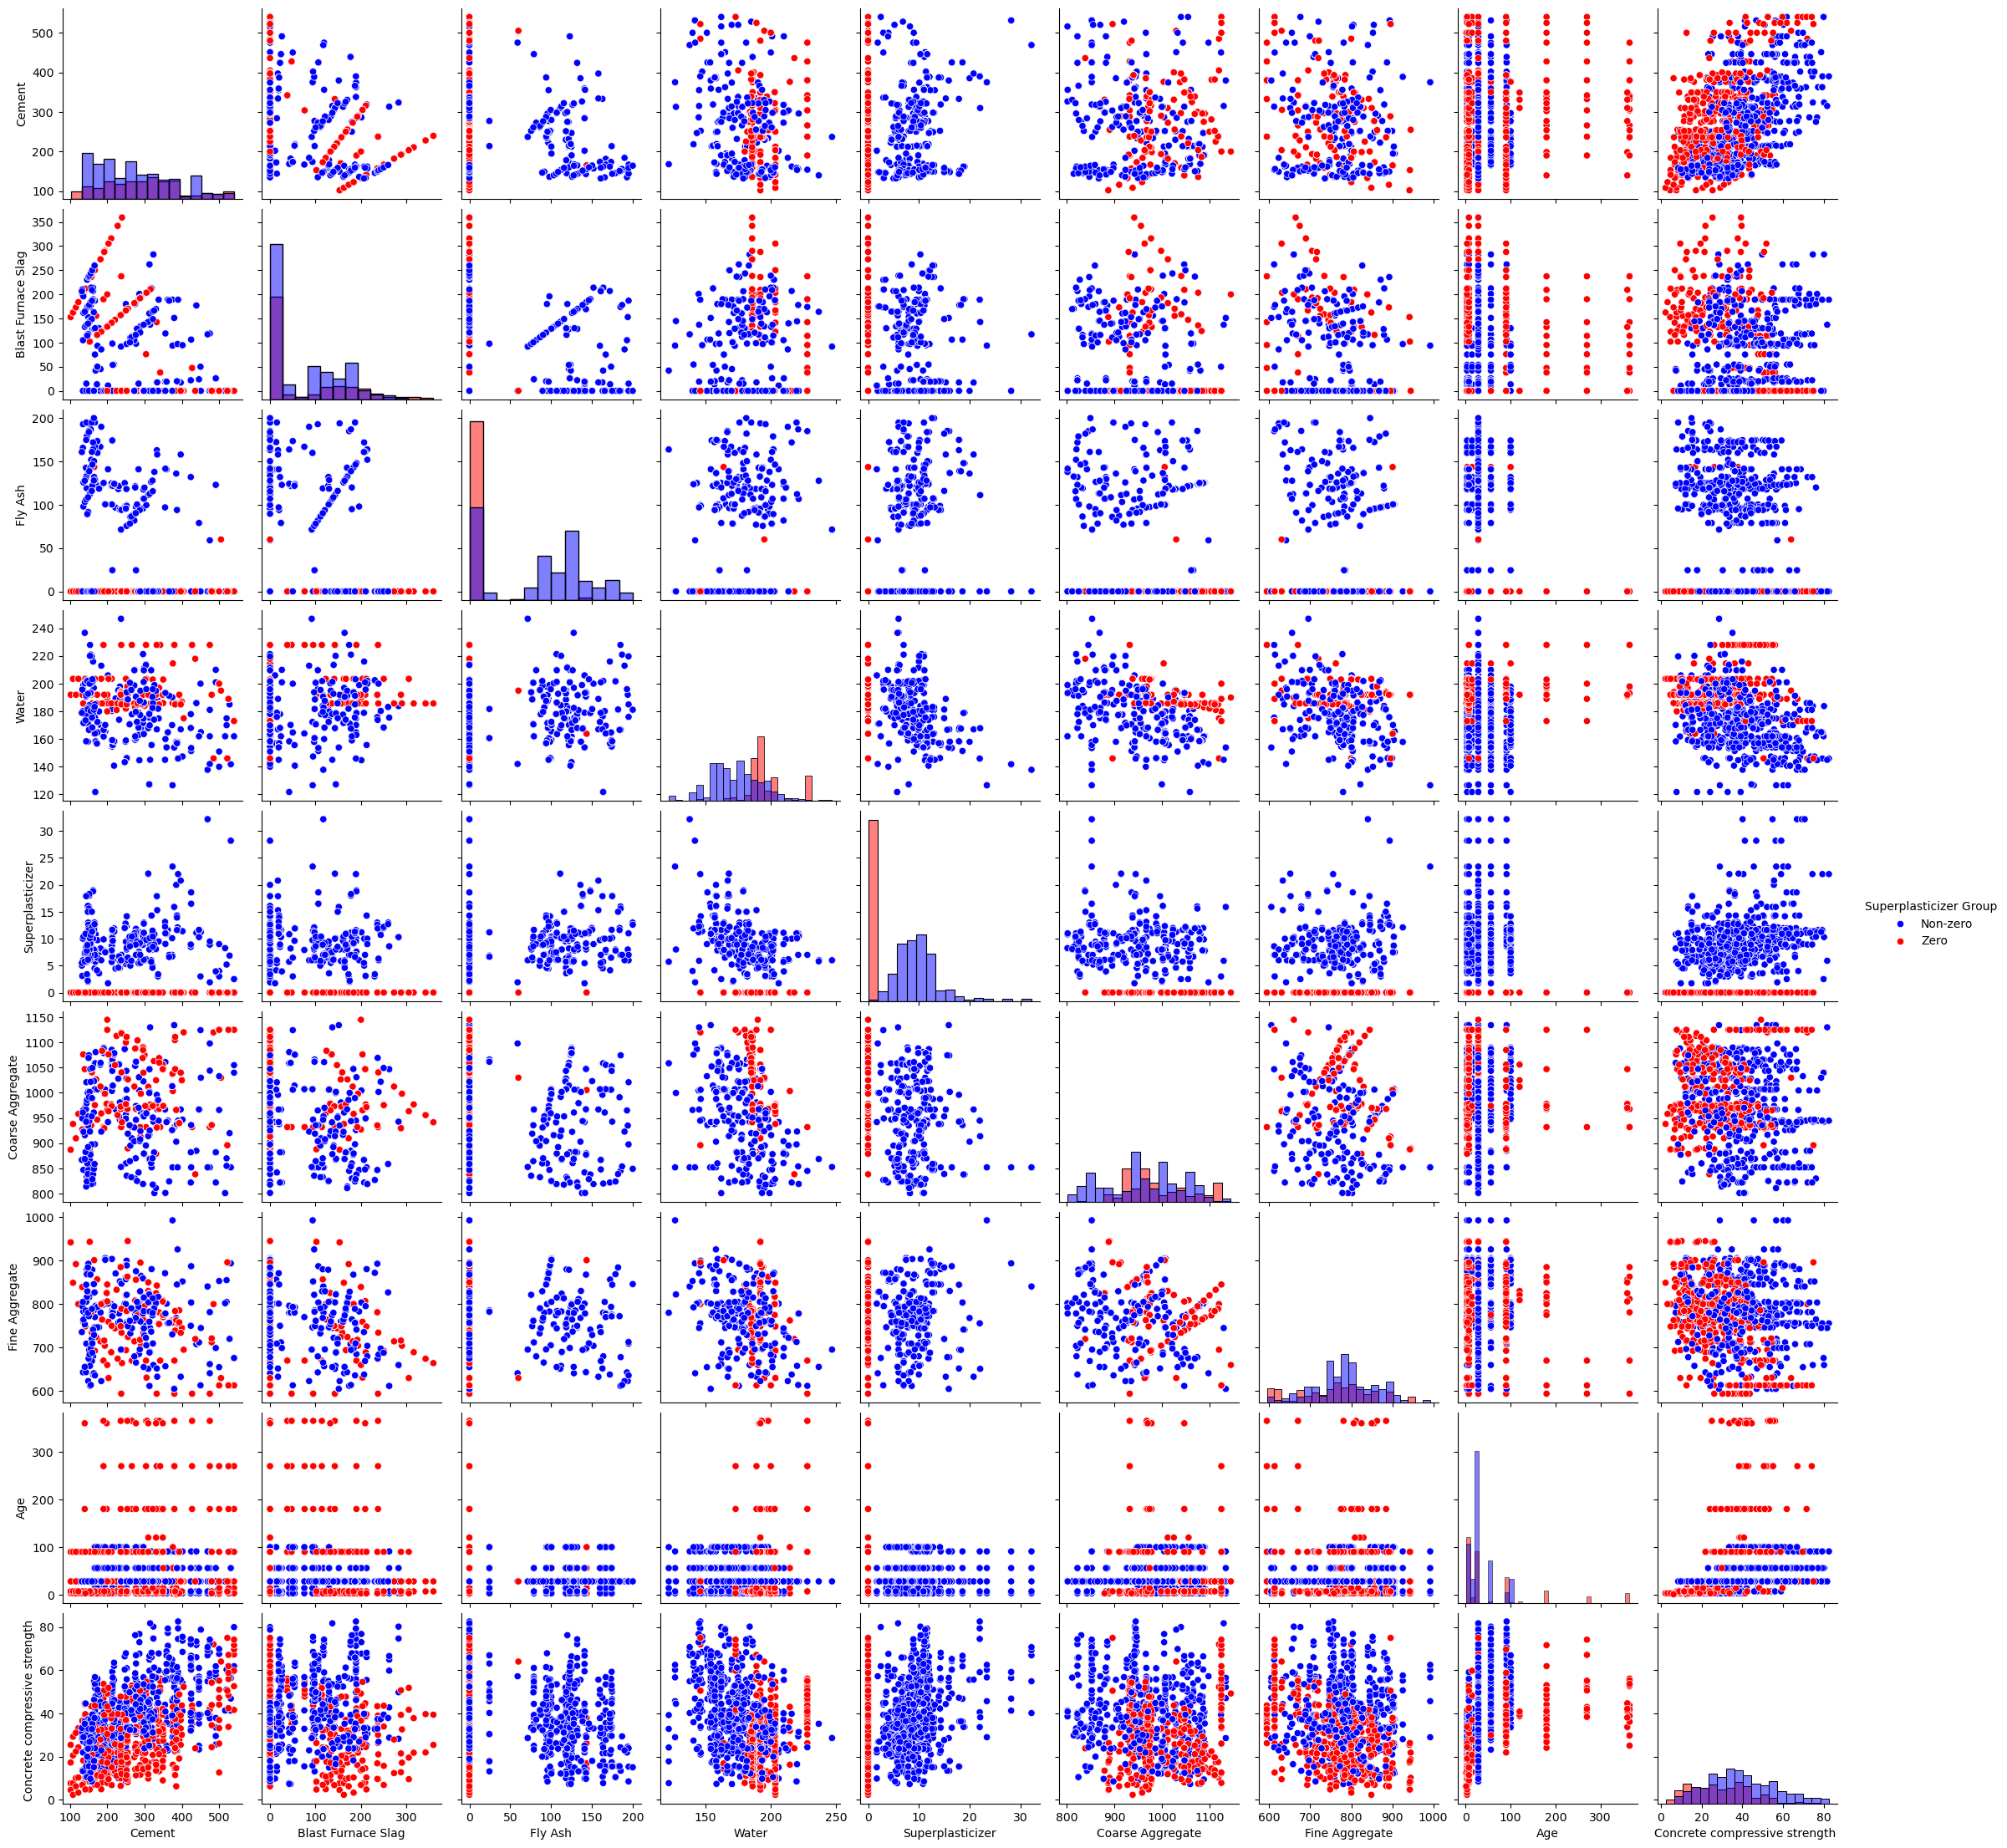

In [12]:
df["Superplasticizer Group"] = df["Superplasticizer"].apply(
    lambda x: "Zero" if x == 0 else "Non-zero"
)

sns.pairplot(
    df,
    hue="Superplasticizer Group",
    diag_kind="hist",
    palette={"Zero": "red", "Non-zero": "blue"}
)

plt.show()

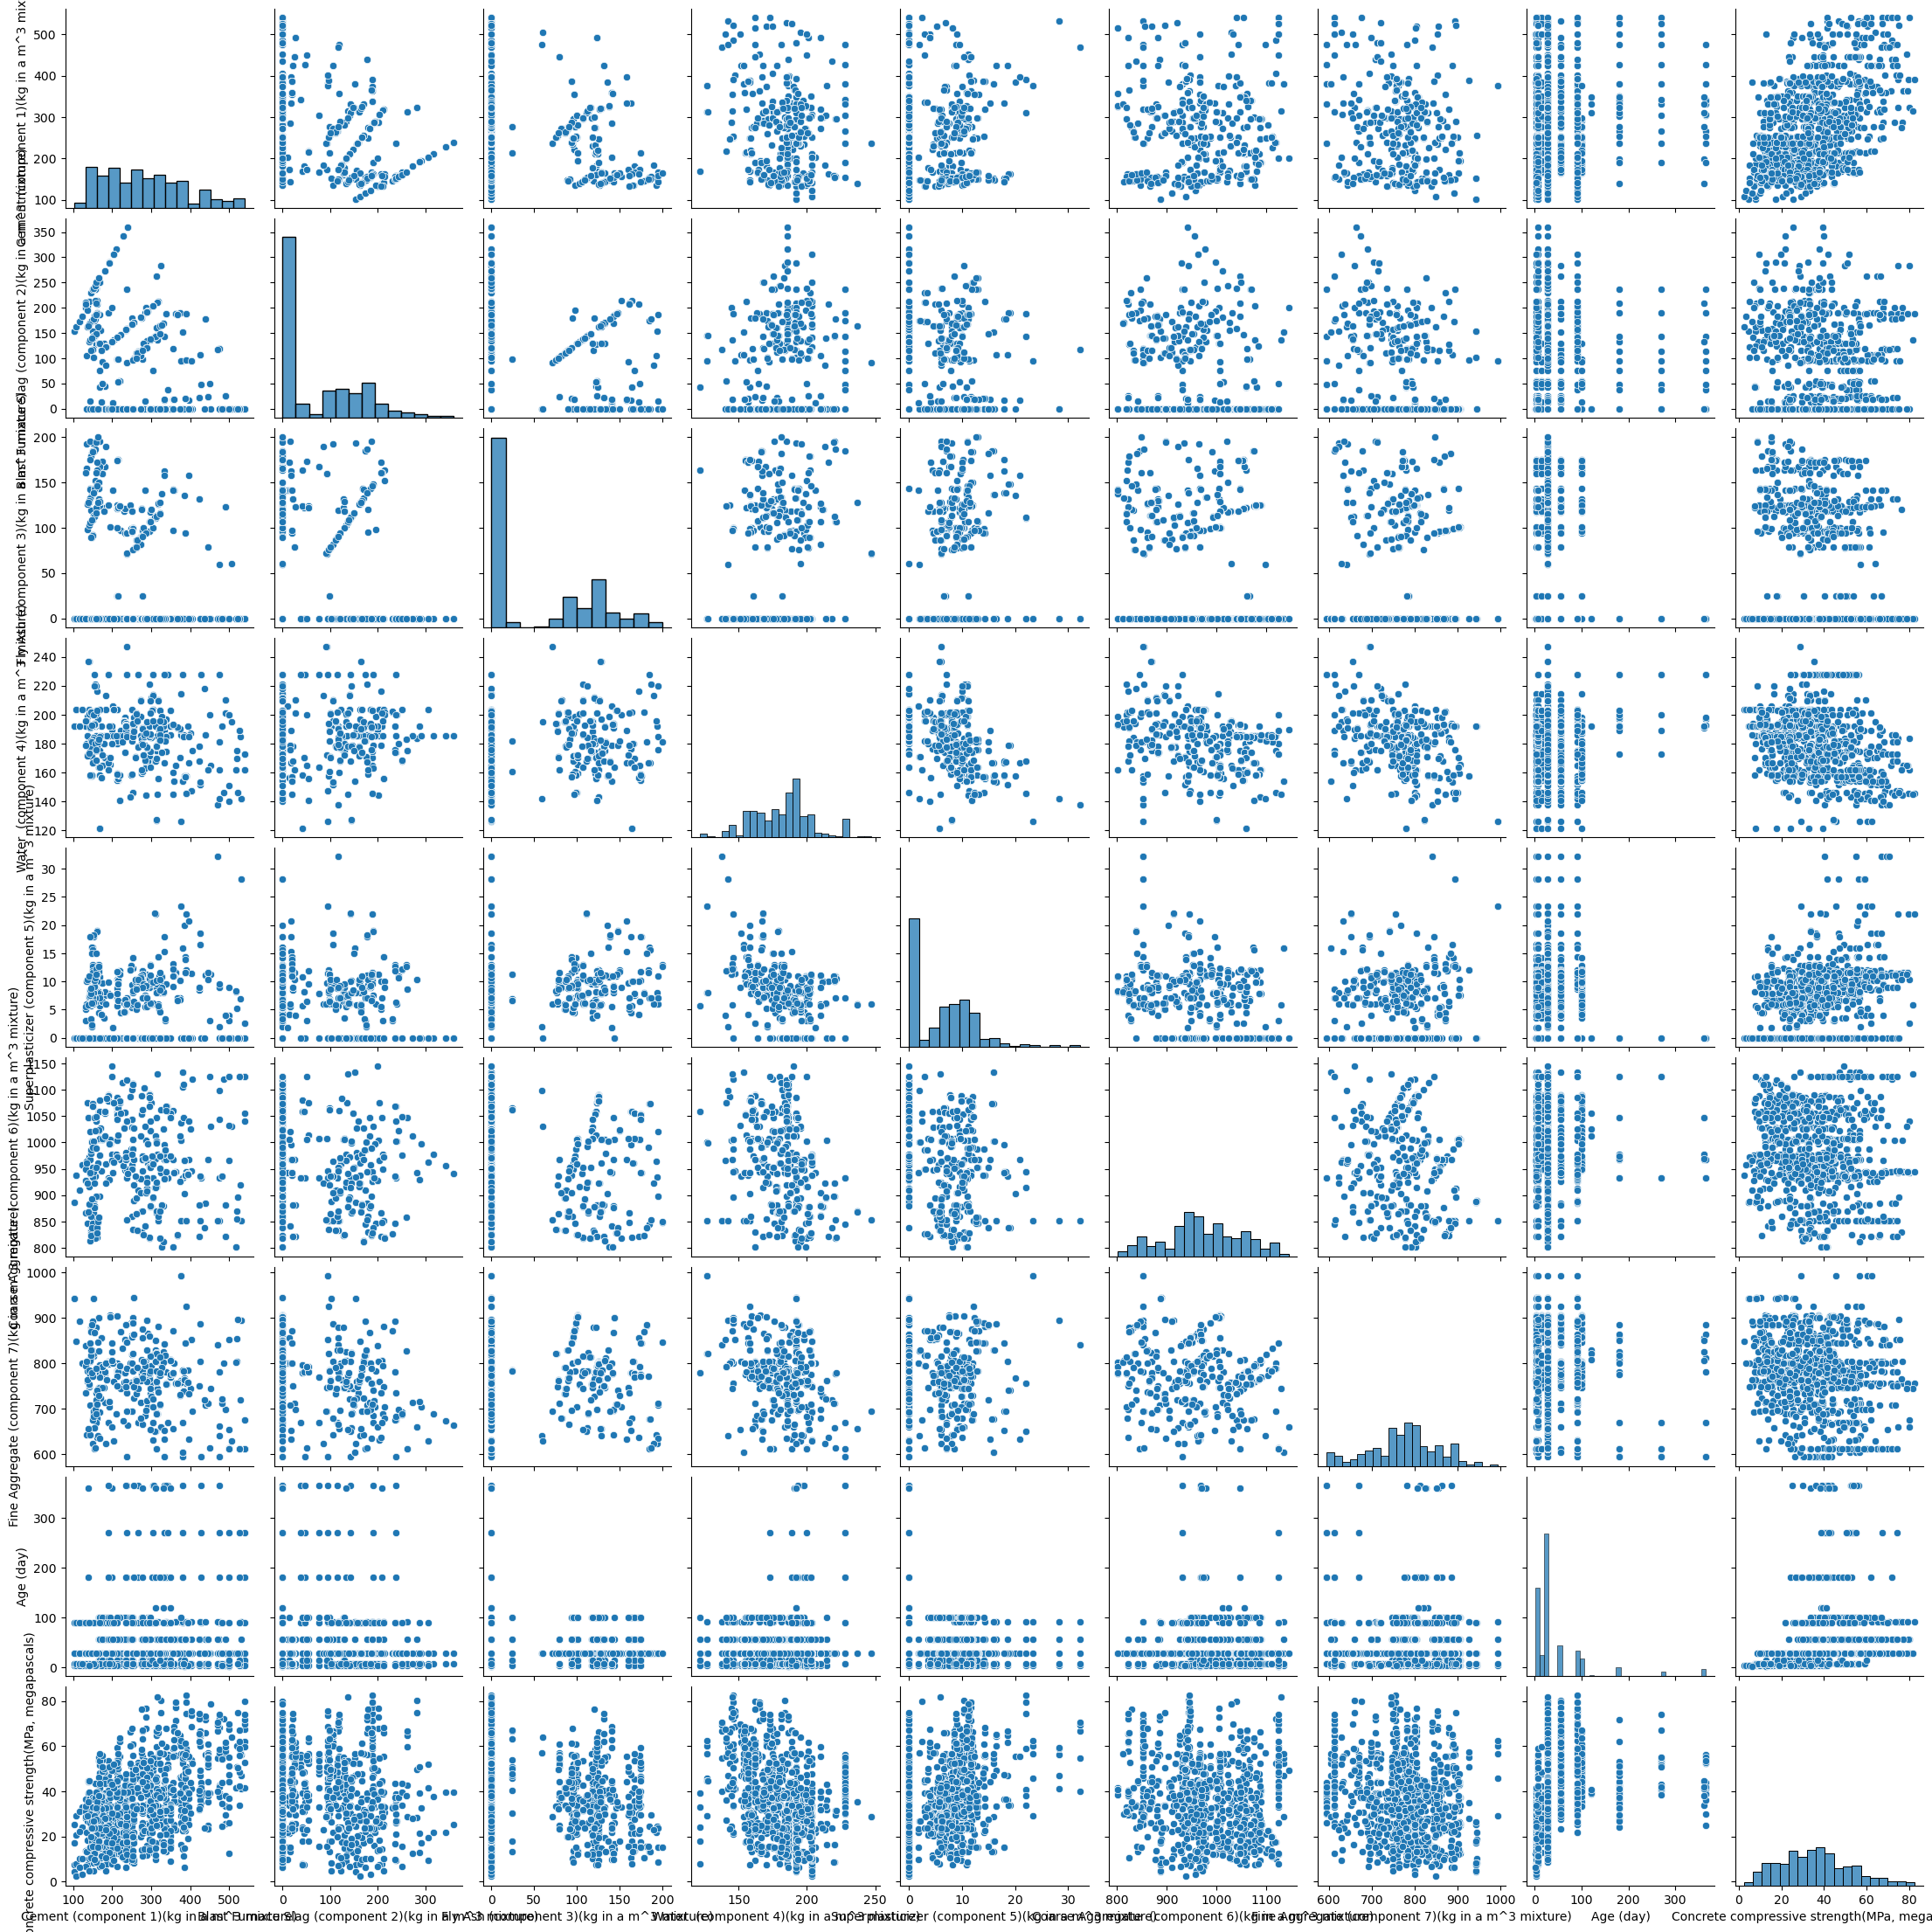

In [6]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.pairplot(df)

plt.show()

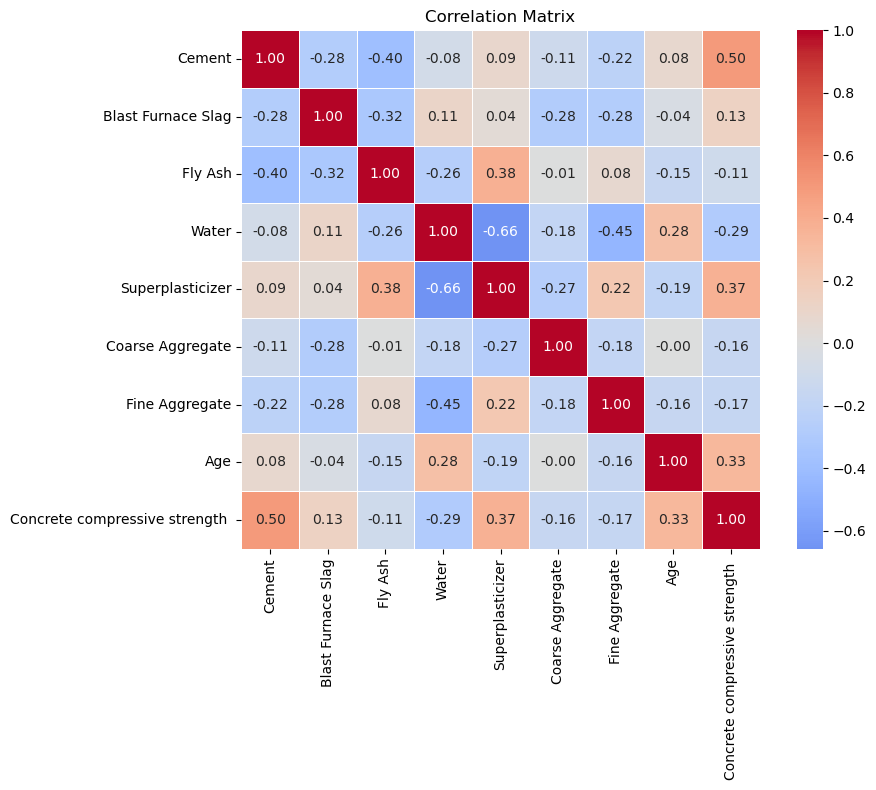

In [13]:
import seaborn as sns
import matplotlib.pyplot as plt

corr = df.corr(numeric_only=True)

plt.figure(figsize=(10, 8))

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True,
    linewidths=0.5
)

plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()